# Analiza wyników i wnioski końcowe

Opracowanie przedstawia ocenę modelu autoenkodera przeznaczonego do wykrywania potencjalnie nieautoryzowanych transakcji. Analizę przeprowadzono na podstawie wyników zapisanych podczas eksperymentów, w szczególności raportu testowego, historii treningu oraz rezultatów optymalizacji hiperparametrów.

Zakres obejmuje metryki klasyfikacji, rozkład błędu rekonstrukcji MSE, analizę niewykrytych oszustw, porównanie z modelem Isolation Forest i ocenę przyjętego kryterium skuteczności. Uzupełnienie stanowią ograniczenia metody oraz interpretacja wyników w kontekście zastosowania antyfraudowego.

## Założenie wstępne

Wykresy z wynikami eksperymentalnymi oznaczono jako **POMIAR**. Oznaczenie **SCENARIUSZ** dotyczy wyłącznie obliczeń hipotetycznych, a nie dodatkowych eksperymentów na modelu.

In [1]:
from pathlib import Path
from io import BytesIO
import json, zipfile, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown, Image
from scipy.stats import norm

plt.rcParams.update({'figure.figsize': (11, 4.8), 'figure.dpi': 105, 'axes.grid': True,
                     'grid.alpha': .20, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.family': 'DejaVu Sans', 'savefig.bbox': 'tight'})
COL = {'ae':'#126A8A', 'base':'#D27840','bad':'#BF4055','good':'#297D66','muted':'#6E8195','dark':'#1D2A3A'}

def locate_archive():
    locations = [Path.cwd(), *Path.cwd().parents]
    for folder in locations:
        for filename in ('artifacts.zip','source_artifacts.zip'):
            p=folder/filename
            if p.is_file(): return p
    raise FileNotFoundError('Połóż artifacts.zip obok notebooka (lub w folderze nadrzędnym).')

archive=locate_archive()
z=zipfile.ZipFile(archive)
ROOT_IN_ZIP='artifacts/tuning/'
def artifact_bytes(relative): return z.read(ROOT_IN_ZIP + relative)
def artifact_json(relative): return json.loads(artifact_bytes(relative))
def artifact_csv(relative): return pd.read_csv(BytesIO(artifact_bytes(relative)))
def artifact_image(relative): display(Image(data=artifact_bytes(relative)))

report=artifact_json('final_model/test_evaluation/report.json')
trial_meta=artifact_json('best_trial.json')
importances=artifact_json('param_importances.json')
history=artifact_json('final_model/training_history.json')
trials=artifact_csv('trials.csv')

OUT=Path.cwd()/'FAZY_8_9_WYKRESY_Z_ARTIFACTS'
OUT.mkdir(parents=True, exist_ok=True)
def savefig(fig, name):
    fig.savefig(OUT/name, dpi=175, facecolor='white')
    plt.show()
print('Źródło:', archive.name, '| ewaluacja:', report['evaluated_at'])
print('Liczba prób Optuny:', len(trials), '| epoki treningu finalnego:',len(history['records']))

Źródło: artifacts.zip | ewaluacja: 2026-10-25 10:50:43
Liczba prób Optuny: 717 | epoki treningu finalnego: 100


## 1. Dane, metodologia i kryteria oceny

Autoenkoder trenowano wyłącznie na transakcjach prawidłowych. Próg detekcji na podstawie MSE wyznaczono na zbiorze walidacyjnym, a końcową ocenę przeprowadzono na niezależnym zbiorze testowym. Założone kryterium skuteczności: **Recall ≥ 85% oraz FPR < 1%**.

Zbiór początkowy zawierał 284 807 transakcji, w tym 492 oszukańcze. Po usunięciu 1 081 duplikatów pozostało 283 726 obserwacji. Zmienną `Time` przekształcono do reprezentacji cyklicznej, a `Amount` transformowano przez `log1p`. Parametry skalowania wyznaczono na zbiorze treningowym. Zbiór testowy obejmuje **42 725 transakcji, w tym 237 oszustw**.

In [2]:
ae=report['autoencoder']; base=report['baseline']
neg=int(report['test_legitimate']); pos=int(report['test_fraud']); N=neg+pos
assert all(int(m['tn']+m['fp'])==neg and int(m['tp']+m['fn'])==pos for m in (ae,base))

def derive(m):
    tn, fp, fn, tp = [int(m[k]) for k in ['tn','fp','fn','tp']]
    return dict(TP=tp,FN=fn,FP=fp,TN=tn,Recall=tp/(tp+fn),FPR=fp/(tn+fp),
                Precision=tp/(tp+fp),F1=2*tp/(2*tp+fp+fn),
                Specificity=tn/(tn+fp),Accuracy=(tp+tn)/(tp+tn+fp+fn),
                PR_AUC=float(m['pr_auc']),ROC_AUC=float(m['roc_auc']))
R=pd.DataFrame({'Autoenkoder':derive(ae),'Isolation Forest':derive(base)}).T
for tag,raw in [('Autoenkoder',ae),('Isolation Forest',base)]:
    for field in ['recall','fpr','precision','f1']:
        assert abs(R.loc[tag,{'recall':'Recall','fpr':'FPR','precision':'Precision','f1':'F1'}[field]]-raw[field]) <1e-10
print('Spójność danych: OK, wszystkie wartości wyliczone ponownie z macierzy pomyłek.')
display(R[['TP','FN','FP','TN','Recall','FPR','Precision','F1','PR_AUC','ROC_AUC']].style.format(
    {k:'{:.2%}' for k in ['Recall','FPR','Precision']}
    | {'F1':'{:.3f}','PR_AUC':'{:.3f}','ROC_AUC':'{:.3f}'}))

Spójność danych: OK, wszystkie wartości wyliczone ponownie z macierzy pomyłek.


,TP,FN,FP,TN,Recall,FPR,Precision,F1,PR_AUC,ROC_AUC
Autoenkoder,199.000000,38.000000,417.000000,42071.000000,83.97%,0.98%,32.31%,0.467,0.745,0.958
Isolation Forest,126.000000,111.000000,423.000000,42065.000000,53.16%,1.00%,22.95%,0.321,0.271,0.951


Podstawowe miary: **Recall = TP / (TP + FN)**, **FPR = FP / (FP + TN)**, **Precision = TP / (TP + FP)**. Ze względu na znaczne niezbalansowanie klas sama dokładność (accuracy) nie stanowi wystarczającej miary skuteczności detekcji.

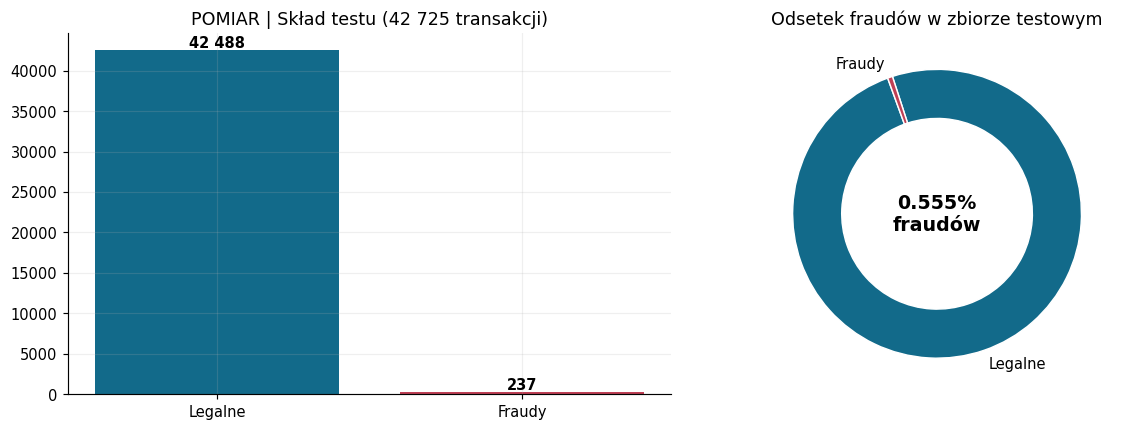

In [3]:
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
axs[0].bar(['Legalne','Fraudy'],[neg,pos],color=[COL['ae'],COL['bad']]);axs[0].set_title('POMIAR | Skład testu (42 725 transakcji)')
for p in axs[0].patches: axs[0].text(p.get_x()+p.get_width()/2,p.get_height(),f'{p.get_height():,.0f}'.replace(',',' '),ha='center',va='bottom',fontweight='bold')
axs[1].pie([neg,pos],labels=['Legalne','Fraudy'],colors=[COL['ae'],COL['bad']],startangle=110,
           wedgeprops={'width':.34,'edgecolor':'white'})
axs[1].text(0,0,f'{pos/N:.3%}\nfraudów',ha='center',va='center',weight='bold',fontsize=13)
axs[1].set_title('Odsetek fraudów w zbiorze testowym')
fig.tight_layout();savefig(fig,'01_klasy_test.png')

## 2. Macierze pomyłek i porównanie modeli

Wyniki autoenkodera i Isolation Forest odnoszą się do tego samego zbioru testowego. W macierzach wiersze odpowiadają klasom rzeczywistym, a kolumny klasom przewidywanym.

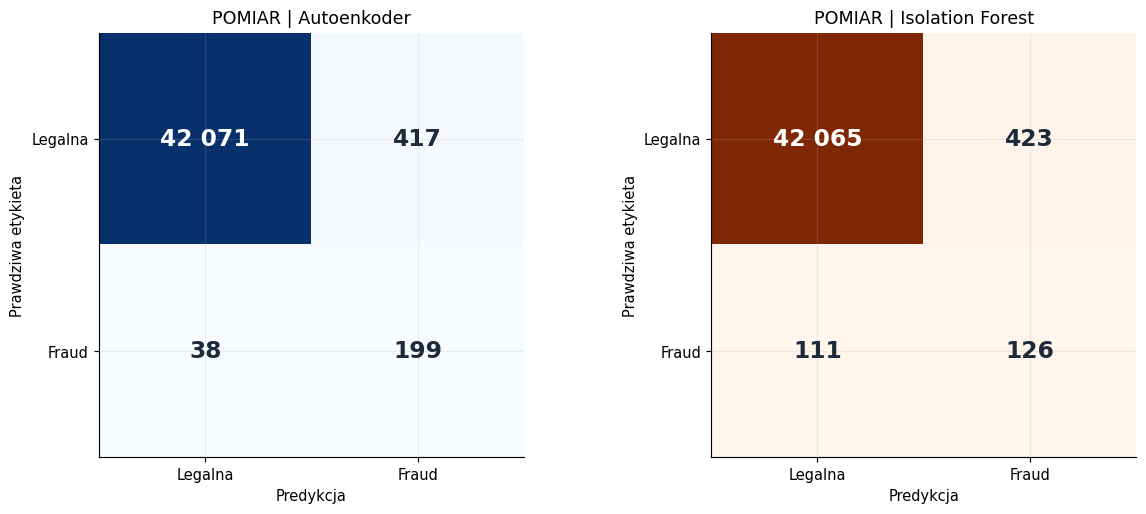

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(tag,m),color in zip(axes,[('Autoenkoder',ae),('Isolation Forest',base)],['Blues','Oranges']):
    vals=np.array([[m['tn'],m['fp']],[m['fn'],m['tp']]])
    ax.imshow(vals,cmap=color)
    for (i,j),v in np.ndenumerate(vals):
        ax.text(j,i,f'{v:,}'.replace(',',' '),ha='center',va='center',fontsize=16,fontweight='bold',color='white' if v>20000 else COL['dark'])
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Legalna','Fraud'],yticklabels=['Legalna','Fraud'],
           xlabel='Predykcja',ylabel='Prawdziwa etykieta',title=f'POMIAR | {tag}')
fig.tight_layout();savefig(fig,'02_macierze_pomylek.png')

### Interpretacja wyników

Autoenkoder poprawnie wykrył **199 fraudów**, pominął **38** i wygenerował **417 fałszywych alarmów**. Isolation Forest wykrył **126 fraudów**, pominął **111** i wygenerował **423 fałszywe alarmy**. Autoenkoder uzyskał zatem **73 dodatkowe trafne wykrycia** przy **6 fałszywych alarmach mniej**.

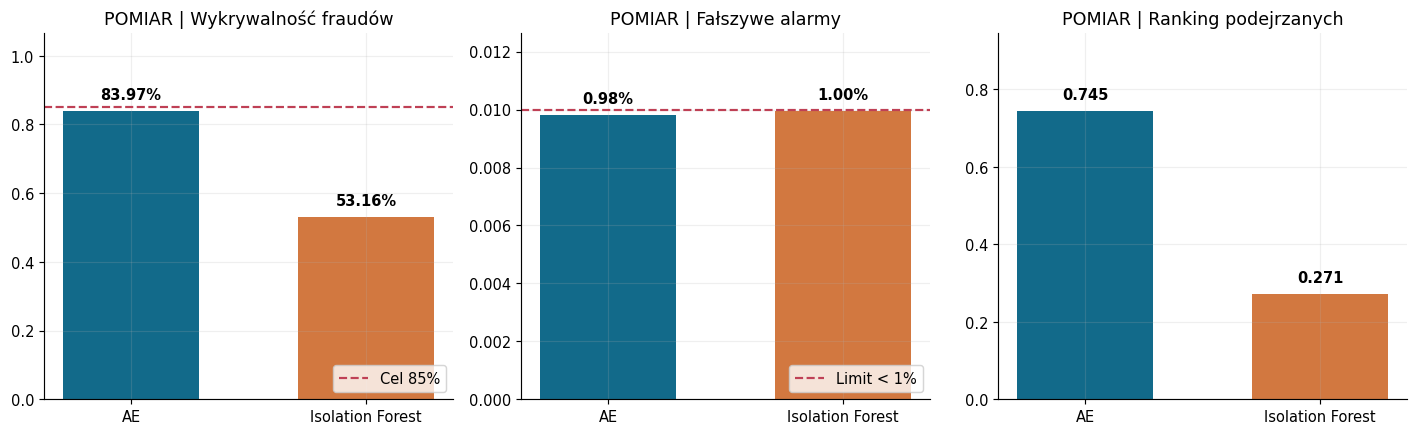

In [5]:
fig,axs=plt.subplots(1,3,figsize=(13.6,4.25))
for ax,metric,label,perc in zip(axs,['Recall','FPR','PR_AUC'],['Wykrywalność fraudów','Fałszywe alarmy','Ranking podejrzanych'],[True,True,False]):
    vals=R[metric].to_numpy();bars=ax.bar(['AE','Isolation Forest'],vals,color=[COL['ae'],COL['base']],width=.58)
    ax.set_title(f'POMIAR | {label}');ax.set_ylim(0,max(vals)*1.27)
    for b,v in zip(bars,vals):ax.text(b.get_x()+b.get_width()/2,v+max(vals)*.04,f'{v:.2%}' if perc else f'{v:.3f}',ha='center',weight='bold')
    if metric=='Recall':ax.axhline(.85,color=COL['bad'],ls='--',label='Cel 85%');ax.legend(loc='lower right')
    if metric=='FPR':ax.axhline(.01,color=COL['bad'],ls='--',label='Limit < 1%');ax.legend(loc='lower right')
fig.tight_layout();savefig(fig,'03_ae_vs_baseline.png')

### Interpretacja ROC-AUC i PR-AUC

Modele uzyskały zbliżone ROC-AUC (0,958 i 0,951), jednak różniły się Recall przy FPR bliskim 1%. Przy silnym niezbalansowaniu klas większą wartość porównawczą mają także Precision i PR-AUC, które wyniosły odpowiednio dla modeli **0,745 i 0,271**. Krzywą Precision–Recall przedstawiono poniżej.

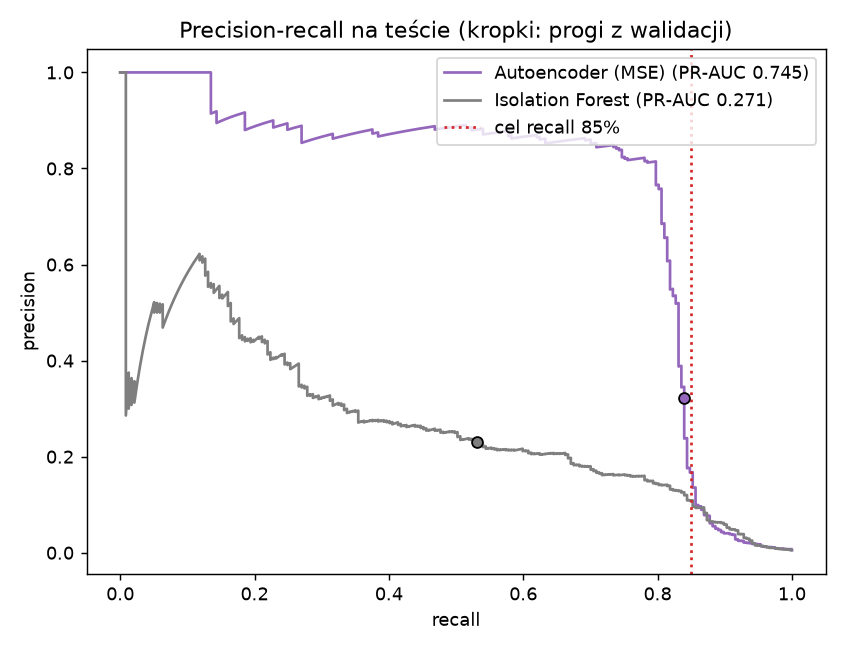

In [6]:
artifact_image('final_model/test_evaluation/precision_recall.png')

## 3. Weryfikacja kryterium skuteczności

Warunek uznaje się za spełniony wyłącznie przy jednoczesnym uzyskaniu **Recall ≥ 85%** oraz **FPR < 1%**.

In [7]:
need_tp=math.ceil(.85*pos)
max_fp=math.ceil(.01*neg)-1  # ostrze < 1%
rows=[('Recall',f'{ae["recall"]:.3%}','≥ 85%',bool(ae['recall']>=.85)),
      ('FPR',f'{ae["fpr"]:.3%}','< 1%',bool(ae['fpr']<.01)),
      ('Minimum wykrytych fraudów',f'{ae["tp"]}',f'{need_tp}',ae['tp']>=need_tp),
      ('Maksymalnie fałszywych alarmów',f'{ae["fp"]}',f'{max_fp}',ae['fp']<=max_fp)]
check=pd.DataFrame(rows,columns=['Warunek','Wynik','Wymaganie','Spełniony'])
check['Ocena']=check['Spełniony'].map({True:'TAK',False:'NIE'})
display(check.drop(columns='Spełniony'))
print(f'Brakuje {need_tp-ae["tp"]} trafień na istniejącym zbiorze testowym; próg pozostaje zamrożony.')

,Warunek,Wynik,Wymaganie,Ocena
0,Recall,83.966%,≥ 85%,NIE
1,FPR,0.981%,< 1%,TAK
2,Minimum wykrytych fraudów,199,202,NIE
3,Maksymalnie fałszywych alarmów,417,424,TAK


Brakuje 3 trafień na istniejącym zbiorze testowym; próg pozostaje zamrożony.


**Wynik:** osiągnięto wymagany FPR, lecz Recall pozostał poniżej 85%. Do osiągnięcia progu zabrakło **trzech dodatkowo wykrytych fraudów**.

## 4. Rozkład błędu rekonstrukcji MSE

Błąd rekonstrukcji MSE stanowi podstawę decyzji detektora. Transakcje o MSE przekraczającym wyznaczony na walidacji próg **1,0083183** klasyfikowane są jako potencjalne oszustwa. Poniżej przedstawiono rozkład uzyskany podczas ewaluacji modelu finalnego.

Próg na walidacji: 1.008318305015564 | Recall walidacja: 80.51% | FPR walidacja: 0.998%


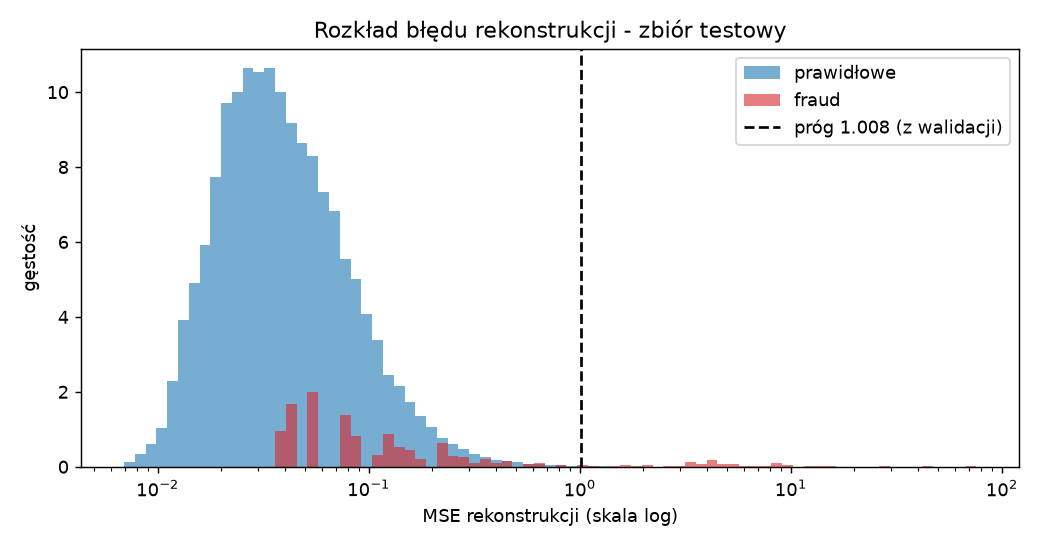

In [8]:
print('Próg na walidacji:',ae['threshold'],'| Recall walidacja:',f'{ae["validation_recall"]:.2%}',
      '| FPR walidacja:',f'{ae["validation_fpr"]:.3%}')
artifact_image('final_model/test_evaluation/mse_distribution.png')

### Mediany błędu rekonstrukcji

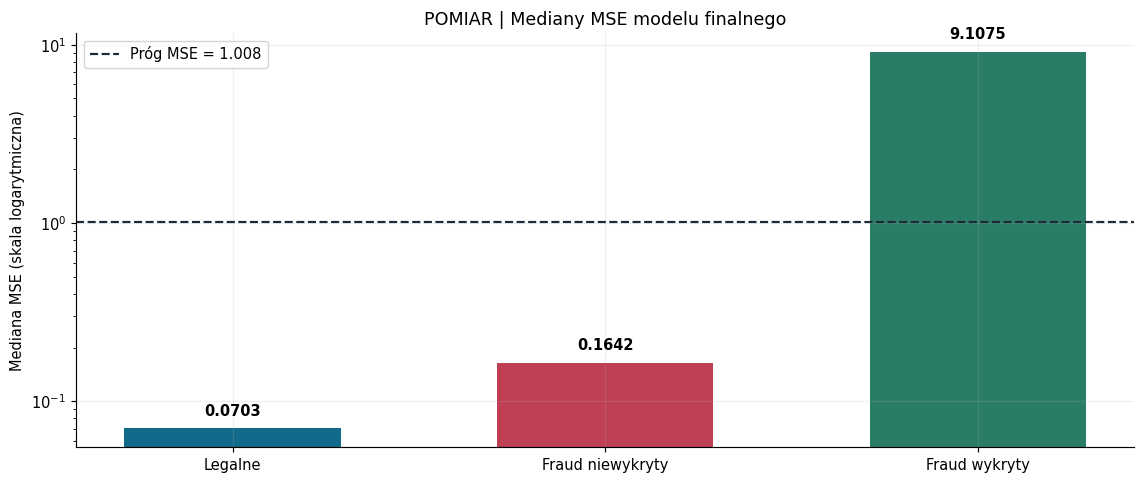

In [9]:
fninfo=report['false_negatives']
medians=pd.Series({'Legalne':fninfo['median_mse_legitimate'],
                   'Fraud niewykryty':fninfo['median_mse_missed'],
                   'Fraud wykryty':fninfo['median_mse_detected']})
fig,ax=plt.subplots(figsize=(11,4.7))
bars=ax.bar(medians.index,medians.values,color=[COL['ae'],COL['bad'],COL['good']],width=.58)
ax.axhline(ae['threshold'],ls='--',color=COL['dark'],label=f'Próg MSE = {ae["threshold"]:.3f}')
ax.set_yscale('log');ax.set_ylabel('Mediana MSE (skala logarytmiczna)');ax.set_title('POMIAR | Mediany MSE modelu finalnego')
for b,v in zip(bars,medians.values): ax.text(b.get_x()+b.get_width()/2,v*1.18,f'{v:.4f}',ha='center',weight='bold')
ax.legend();fig.tight_layout();savefig(fig,'04_mediany_mse_final.png')

### Interpretacja rozkładu

Mediana MSE transakcji prawidłowych wyniosła **0,0703**, wykrytych fraudów **9,1075**, a niewykrytych fraudów **0,1642**. Wysoki błąd rekonstrukcji stanowi więc istotny sygnał anomalii, ale część oszustw uzyskuje wartości zbliżone do transakcji prawidłowych.

Dostępne artefakty zawierają wykres rozkładu i statystyki zagregowane, ale nie pełną listę indywidualnych wyników MSE, nie umożliwiają zatem niezależnego wyznaczenia średnich dla całego testu.

## 5. Analiza niewykrytych oszustw (false negatives)

Na zbiorze testowym **38 fraudów** nie przekroczyło progu detekcji autoenkodera. Zgodnie z raportem wszystkie te przypadki pozostały niewykryte również przez Isolation Forest.

,Indeks w teście,MSE,% progu,% legalnych poniżej MSE,Wykryty przez IF
0,5530,0.0402,4.0%,25.7%,False
1,26452,0.0408,4.0%,26.2%,False
2,37338,0.0451,4.5%,30.2%,False
3,8989,0.0527,5.2%,36.7%,False
4,3961,0.0539,5.3%,37.9%,False
5,17697,0.0548,5.4%,38.6%,False
6,12782,0.0731,7.2%,51.8%,False
7,9073,0.0774,7.7%,54.3%,False
8,15528,0.0781,7.7%,54.7%,False
9,26115,0.0834,8.3%,57.5%,False


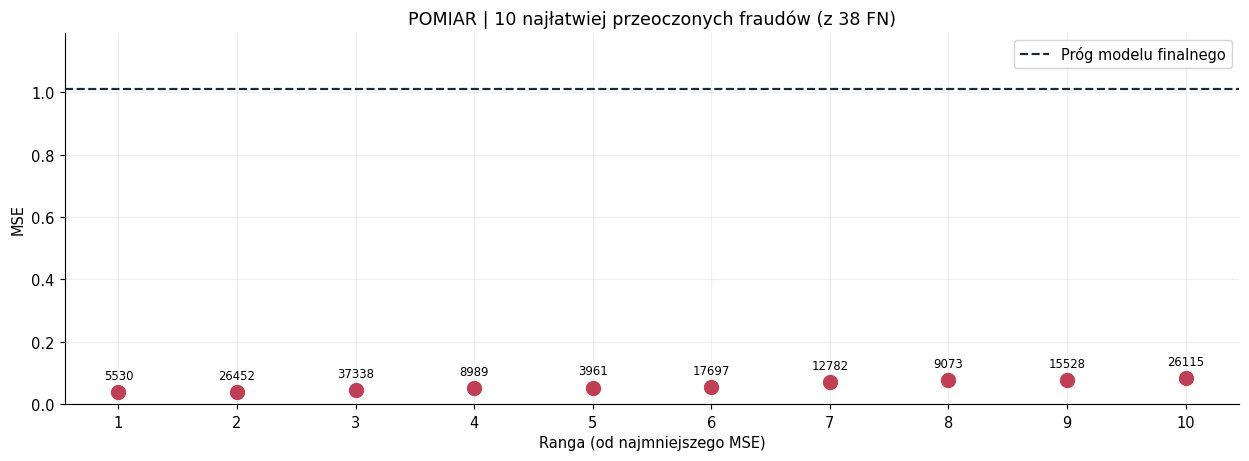

In [10]:
hard=pd.DataFrame(fninfo['hardest_cases'])
hard['% progu']=100*hard['share_of_threshold']
hard['% legalnych poniżej MSE']=hard['legitimate_percentile']
display(hard[['test_row','mse','% progu','% legalnych poniżej MSE','detected_by_baseline']]
        .rename(columns={'test_row':'Indeks w teście','mse':'MSE','detected_by_baseline':'Wykryty przez IF'})
        .style.format({'MSE':'{:.4f}','% progu':'{:.1f}%','% legalnych poniżej MSE':'{:.1f}%'}))
fig,ax=plt.subplots(figsize=(12,4.5))
ax.scatter(range(1,len(hard)+1),hard['mse'],s=90,color=COL['bad'],zorder=3)
ax.axhline(ae['threshold'],label='Próg modelu finalnego',color=COL['dark'],ls='--')
for i,r in enumerate(hard.itertuples(index=False),start=1):
    ax.annotate(str(r.test_row),(i,r.mse),xytext=(0,9),textcoords='offset points',ha='center',fontsize=8)
ax.set(xticks=list(range(1,len(hard)+1)),xlabel='Ranga (od najmniejszego MSE)',ylabel='MSE',
       title='POMIAR | 10 najłatwiej przeoczonych fraudów (z 38 FN)')
ax.set_ylim(0,1.18*ae['threshold']);ax.legend();fig.tight_layout();savefig(fig,'05_najtrudniejsze_fraudy.png')

Najtrudniejszy przypadek uzyskał MSE około **0,040**, czyli **4% wartości progu**. Tak niski błąd utrudnia odróżnienie transakcji od klasy prawidłowej. Obniżenie progu może zwiększyć Recall, lecz wiąże się z ryzykiem wzrostu liczby fałszywych alarmów.

## 6. Analiza błędów rekonstrukcji poszczególnych cech

Na podstawie raportu porównano średnie błędy rekonstrukcji wybranych cech dla trzech grup: transakcji prawidłowych, wykrytych oszustw i oszustw niewykrytych.

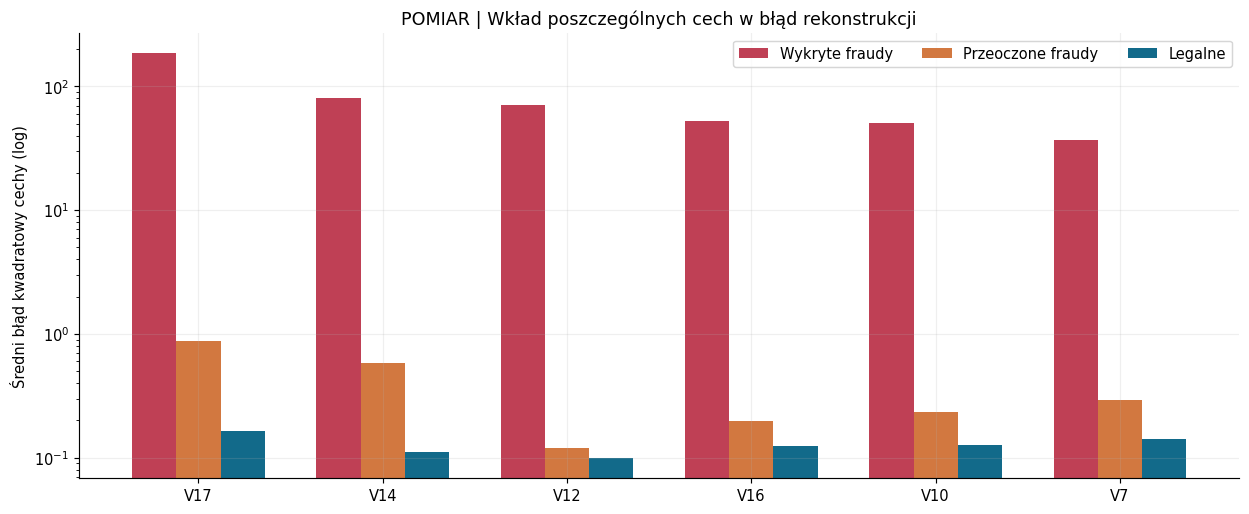

,detected_fraud,missed_fraud,legitimate
feature,,,
V17,184.272,0.871,0.163
V14,79.848,0.577,0.112
V12,71.242,0.119,0.099
V16,52.152,0.196,0.125
V10,50.444,0.234,0.126
V7,36.587,0.294,0.142


In [11]:
features=pd.DataFrame(fninfo['feature_errors']).set_index('feature')
fig,ax=plt.subplots(figsize=(12,5.0))
x=np.arange(len(features));w=.24
for idx,(column,label,color) in enumerate([('detected_fraud','Wykryte fraudy',COL['bad']),
                                           ('missed_fraud','Przeoczone fraudy',COL['base']),
                                           ('legitimate','Legalne',COL['ae'])]):
    ax.bar(x+(idx-1)*w,features[column],width=w,label=label,color=color)
ax.set_xticks(x,features.index);ax.set_yscale('log');ax.set_ylabel('Średni błąd kwadratowy cechy (log)')
ax.set_title('POMIAR | Wkład poszczególnych cech w błąd rekonstrukcji')
ax.legend(ncol=3);fig.tight_layout();savefig(fig,'06_bledy_cech.png')
display(features.style.format('{:.3f}'))

Największy kontrast odnotowano m.in. dla cechy **V17**: średni błąd wyniósł około **184** wśród wykrytych fraudów, **0,87** wśród niewykrytych i **0,16** dla transakcji prawidłowych. Podobną zależność zaobserwowano dla V14. Ponieważ cechy V1–V28 są anonimowymi składowymi PCA, nie można bezpośrednio przypisać im znaczenia biznesowego.

## 7. Przebieg treningu modelu finalnego

Poniżej przedstawiono wyniki ze **100 epok treningu**. Analiza obejmuje zmiany błędu uczenia i walidacji oraz Recall na zbiorze walidacyjnym.

,epoch,train_loss,validation_loss,validation_fraud_recall,learning_rate
95,96,0.335350,0.146124,0.813559,0.001479
96,97,0.333164,0.146983,0.805085,0.001479
97,98,0.333819,0.146151,0.805085,0.001479
98,99,0.332817,0.147017,0.813559,0.000917
99,100,0.332435,0.145629,0.809322,0.000917


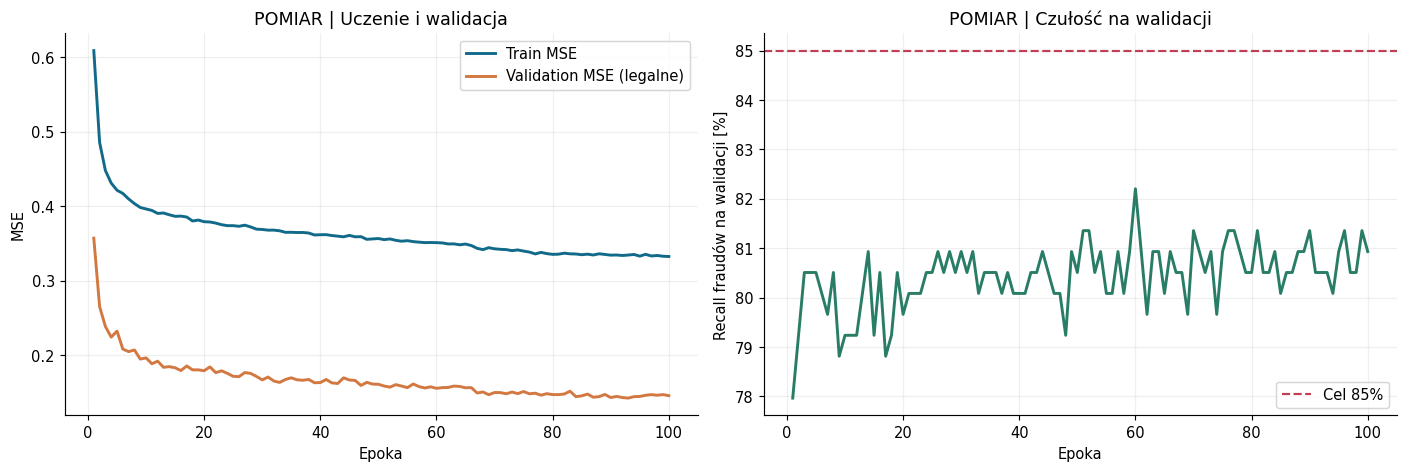

Zapisana historia: 100 epok; najlepsza epoka wg rekordu: 93 | early stopping: False


In [12]:
h=pd.DataFrame(history['records']);display(h[['epoch','train_loss','validation_loss','validation_fraud_recall','learning_rate']].tail())
fig,axs=plt.subplots(1,2,figsize=(13.5,4.6))
axs[0].plot(h.epoch,h.train_loss,label='Train MSE',color=COL['ae'],lw=2)
axs[0].plot(h.epoch,h.validation_loss,label='Validation MSE (legalne)',color=COL['base'],lw=2)
axs[0].set(xlabel='Epoka',ylabel='MSE',title='POMIAR | Uczenie i walidacja');axs[0].legend()
axs[1].plot(h.epoch,100*h.validation_fraud_recall,color=COL['good'],lw=2)
axs[1].axhline(85,color=COL['bad'],ls='--',label='Cel 85%')
axs[1].set(xlabel='Epoka',ylabel='Recall fraudów na walidacji [%]',title='POMIAR | Czułość na walidacji')
axs[1].legend();fig.tight_layout();savefig(fig,'07_trening_100_epok.png')
print('Zapisana historia:',len(h),'epok; najlepsza epoka wg rekordu:',history['best_epoch'],
      '| early stopping:', history['stopped_early'])

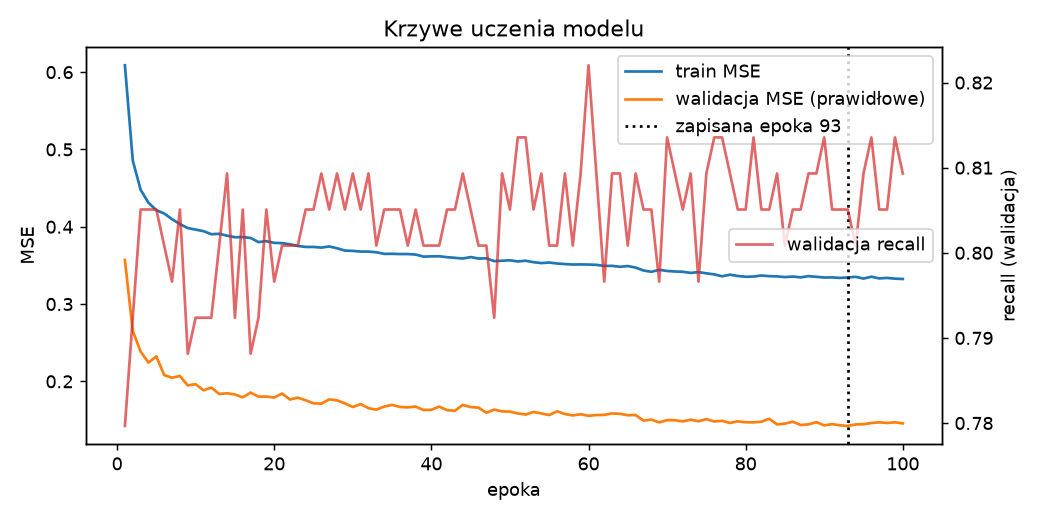

In [13]:
artifact_image('final_model/test_evaluation/learning_curves.png')

### Wynik strojenia i ponownego treningu

Najlepsza próba zapisana w `best_trial.json` osiągnęła **82,2% Recall na walidacji**. Po ponownym treningu wybranej konfiguracji model finalny uzyskał **80,5% na walidacji** oraz **84,0% na teście**.

## 8. Optymalizacja hiperparametrów z użyciem Optuny

Przeprowadzono **717 prób**, z czego **411 zakończono** (`COMPLETE`), a **306 przerwano** (`PRUNED`). Przebieg optymalizacji przedstawia najlepszy dotychczas wynik walidacyjny.

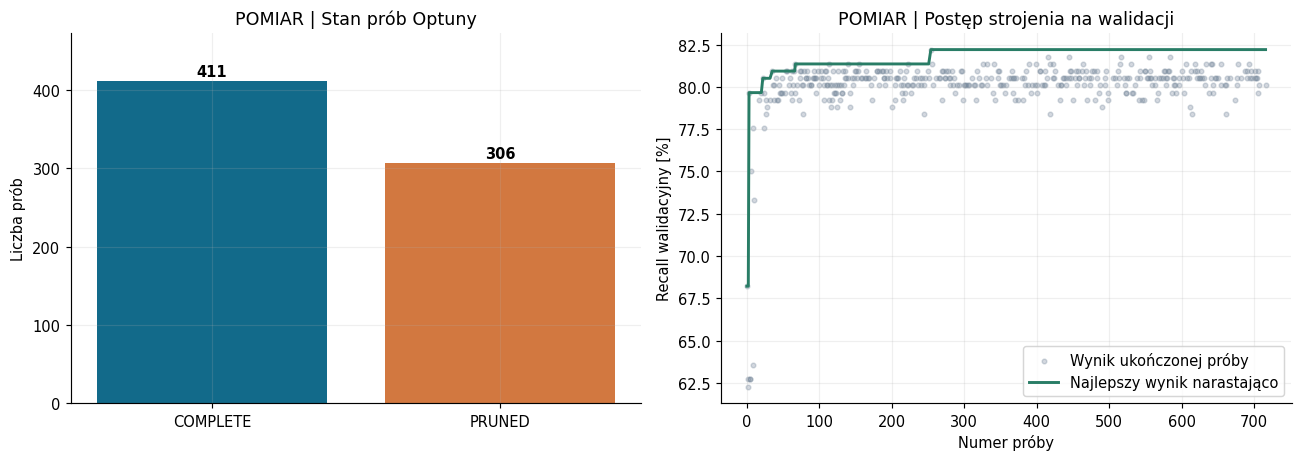

Najlepsza próba: 254 | wynik walidacyjny: 82.20%


In [14]:
counts=trials.state.value_counts();done=trials.query("state == 'COMPLETE'").sort_values('number').copy()
fig,axs=plt.subplots(1,2,figsize=(12.5,4.5))
axs[0].bar(counts.index,counts.values,color=[COL['ae'] if q=='COMPLETE' else COL['base'] for q in counts.index])
for i,n in enumerate(counts.values):axs[0].text(i,n+7,str(n),ha='center',weight='bold')
axs[0].set(title='POMIAR | Stan prób Optuny',ylabel='Liczba prób',ylim=(0,max(counts)*1.15))
axs[1].scatter(done.number,100*done.value,s=10,alpha=.30,color=COL['muted'],label='Wynik ukończonej próby')
axs[1].plot(done.number,100*done.value.cummax(),lw=2,color=COL['good'],label='Najlepszy wynik narastająco')
axs[1].set(title='POMIAR | Postęp strojenia na walidacji',xlabel='Numer próby',ylabel='Recall walidacyjny [%]');axs[1].legend()
fig.tight_layout();savefig(fig,'08_optuna_proby_i_postep.png')
print('Najlepsza próba:',trial_meta['number'],'| wynik walidacyjny:',f"{trial_meta['validation_fraud_recall']:.2%}")

,Liczba ukończonych,Najlepszy recall,Mediana recall
params_hidden_layers,,,
1,4,80.08%,79.66%
2,41,80.93%,80.08%
3,287,82.20%,80.51%
4,79,81.36%,80.51%


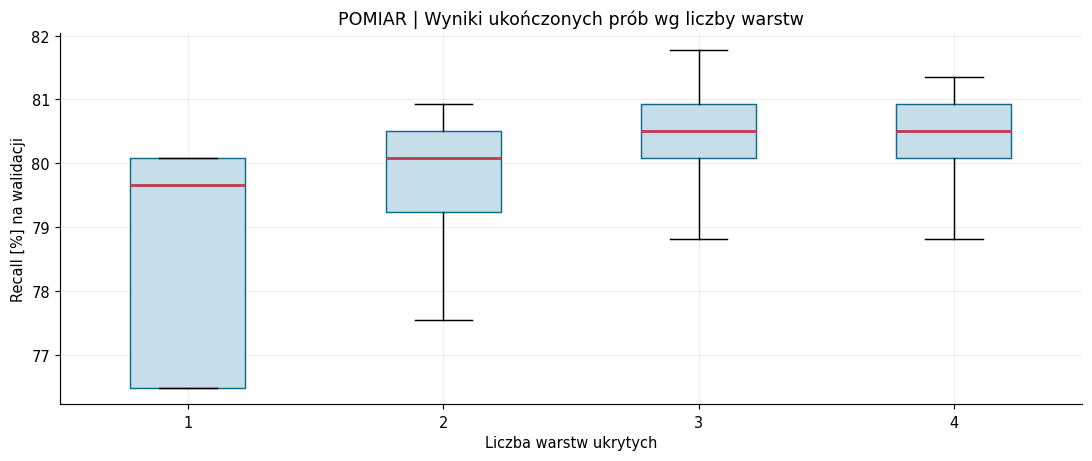

In [15]:
by_layers=done.groupby('params_hidden_layers').value.agg(['count','max','median']).rename(
    columns={'count':'Liczba ukończonych','max':'Najlepszy recall','median':'Mediana recall'})
display(by_layers.style.format({'Najlepszy recall':'{:.2%}','Mediana recall':'{:.2%}'}))
fig,ax=plt.subplots(figsize=(10.5,4.5))
groups=[100*done.loc[done.params_hidden_layers==k,'value'].values for k in sorted(done.params_hidden_layers.unique())]
ax.boxplot(groups,tick_labels=[str(x) for x in sorted(done.params_hidden_layers.unique())],showfliers=False,patch_artist=True,
           boxprops={'facecolor':'#C5DEE8','edgecolor':COL['ae']},medianprops={'color':COL['bad'],'linewidth':2})
ax.set(xlabel='Liczba warstw ukrytych',ylabel='Recall [%] na walidacji',title='POMIAR | Wyniki ukończonych prób wg liczby warstw')
fig.tight_layout();savefig(fig,'09_optuna_liczba_warstw.png')

Liczba prób dla poszczególnych architektur nie była jednakowa, ponieważ Optuna adaptacyjnie dobiera konfiguracje. Najlepsza zakończona próba dla sieci trzywarstwowej osiągnęła około **82,2% Recall na walidacji**.

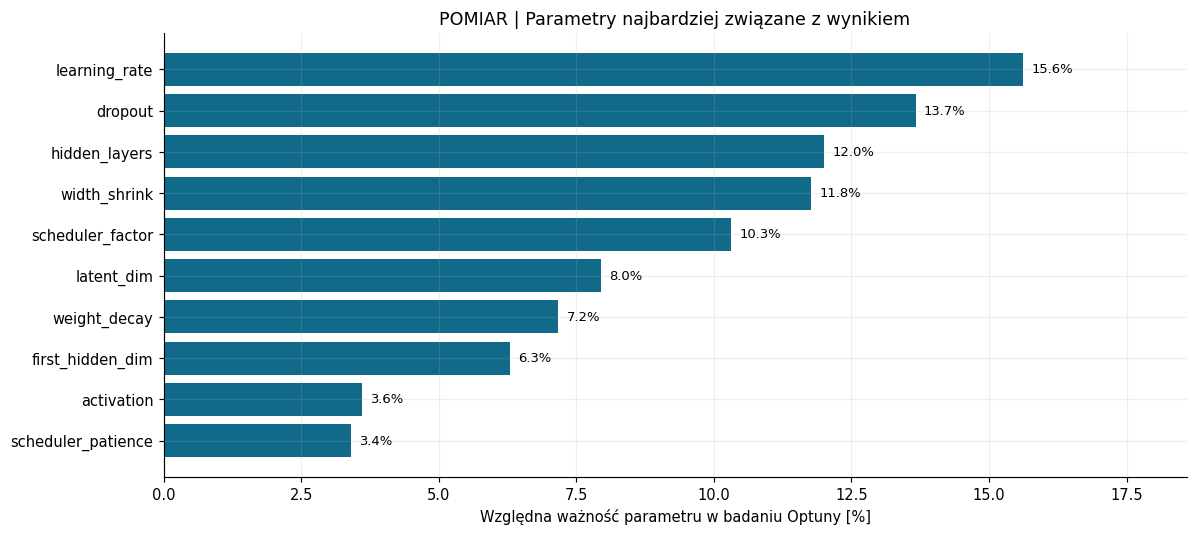

In [16]:
imp=pd.Series(importances,dtype=float).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(11.5,5.2))
plotimp=imp.head(10).sort_values()
ax.barh(plotimp.index,100*plotimp.values,color=COL['ae'])
ax.set(xlabel='Względna ważność parametru w badaniu Optuny [%]',title='POMIAR | Parametry najbardziej związane z wynikiem')
for i,v in enumerate(plotimp):ax.text(100*v+.15,i,f'{100*v:.1f}%',va='center',fontsize=9)
ax.set_xlim(0,max(plotimp.values)*119);fig.tight_layout();savefig(fig,'10_importance_hiperparametry.png')

Największą ważność w analizie hiperparametrów uzyskały: **learning rate (15,6%)**, **dropout (13,7%)**, **liczba warstw (12,0%)** i **tempo zwężania sieci (11,8%)**.

## 9. Niepewność oszacowania Recall

Wartość Recall **199/237 = 83,97%** wyznaczono na podstawie ograniczonej liczby oszustw w teście. Dla tej proporcji obliczono **95% przedział ufności Wilsona**. 

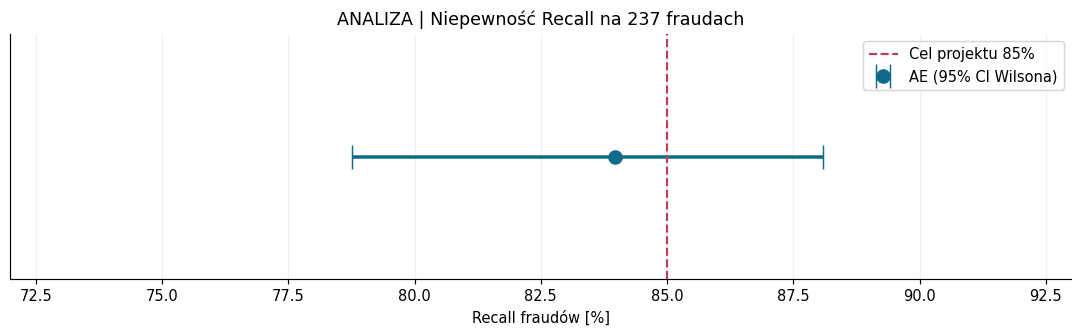

95% CI Wilsona: 78.76% – 88.09%; cel 85% leży w przedziale: True


In [17]:
def wilson_interval(k,n,confidence=.95):
    z=norm.ppf(1-(1-confidence)/2);p=k/n;d=1+z*z/n
    ctr=(p+z*z/(2*n))/d
    rad=z*np.sqrt((p*(1-p)/n)+(z*z/(4*n*n)))/d
    return ctr-rad,ctr+rad
lo,hi=wilson_interval(ae['tp'],pos)
fig,ax=plt.subplots(figsize=(10.4,3.3))
ax.errorbar([100*ae['recall']],[0],xerr=[[100*(ae['recall']-lo)],[100*(hi-ae['recall'])]],fmt='o',capsize=8,
            markersize=9,color=COL['ae'],lw=2.4,label='AE (95% CI Wilsona)')
ax.axvline(85,color=COL['bad'],ls='--',label='Cel projektu 85%')
ax.set(xlabel='Recall fraudów [%]',yticks=[],xlim=(72,93),title='ANALIZA | Niepewność Recall na 237 fraudach')
ax.legend();fig.tight_layout();savefig(fig,'11_przedzial_ufnosci.png')
print(f'95% CI Wilsona: {lo:.2%} – {hi:.2%}; cel 85% leży w przedziale:',lo<=.85<=hi)

Przedział ufności obejmuje wartość 85%, co wskazuje na niepewność oszacowania skuteczności w populacji. Nie zmienia to oceny wyniku testowego: **przyjęte kryterium Recall nie zostało spełnione**.

## 10. Fałszywe alarmy a częstość występowania oszustw

Autoenkoder wygenerował **616 alarmów**, z których **199 było trafnych**, a **417 fałszywych**. Uzyskane **Precision wyniosło 32,3%**. Dodatkowa analiza scenariuszowa przedstawia zależność Precision od udziału fraudów przy założeniu stałego Recall i FPR.

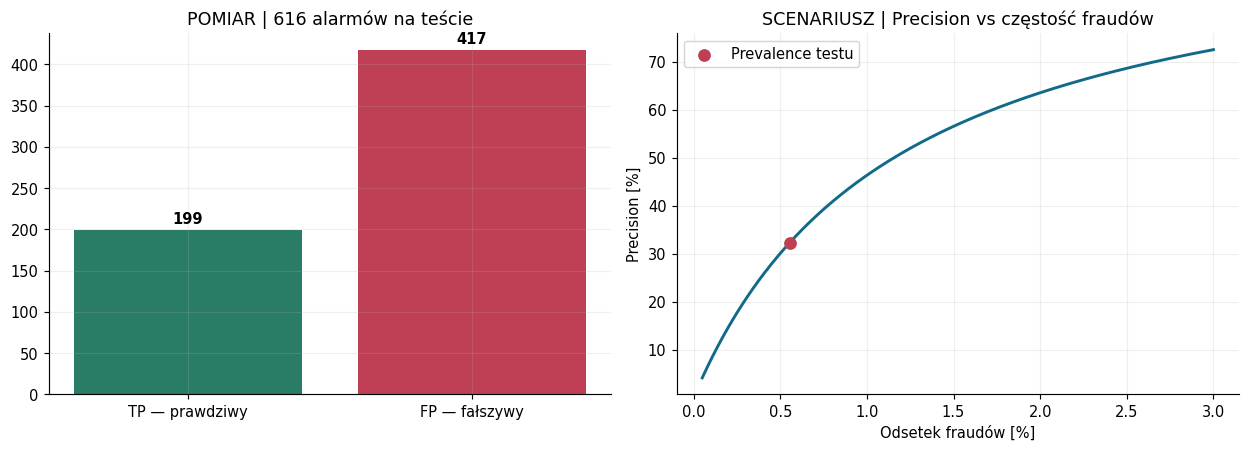

In [18]:
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
axs[0].bar(['TP — prawdziwy','FP — fałszywy'],[ae['tp'],ae['fp']],color=[COL['good'],COL['bad']])
axs[0].set_title(f'POMIAR | {ae["tp"]+ae["fp"]} alarmów na teście')
for i,v in enumerate([ae['tp'],ae['fp']]):axs[0].text(i,v+8,str(v),ha='center',weight='bold')
prevalences=np.linspace(.0005,.03,200)
scenario=lambda p: (p*ae['recall'])/(p*ae['recall']+(1-p)*ae['fpr'])
axs[1].plot(100*prevalences,100*scenario(prevalences),color=COL['ae'],lw=2)
axs[1].scatter([100*pos/N],[100*ae['precision']],color=COL['bad'],s=60,zorder=5,label='Prevalence testu')
axs[1].set(xlabel='Odsetek fraudów [%]',ylabel='Precision [%]',title='SCENARIUSZ | Precision vs częstość fraudów')
axs[1].legend();fig.tight_layout();savefig(fig,'12_alarmy_i_prevalence.png')

Niski udział fraudów powoduje, że nawet FPR poniżej 1% może generować znaczną liczbę nieuzasadnionych alarmów. Z perspektywy zastosowania operacyjnego istotne są zatem zarówno Recall, jak i Precision oraz przewidywana liczba alertów.

## 11. Wydajność obliczeniowa

Czasy treningu i predykcji pochodzą z `report.json` i dotyczą eksperymentu wykonanego z użyciem **NVIDIA L4**. Nie stanowią bezpośredniego oszacowania wydajności systemu produkcyjnego, która zależy również od przetwarzania danych i warunków infrastrukturalnych.

,Operacja,Wartość,Jednostka
0,Trening AE,177.735,s
1,Test AE,0.215,s
2,Trening baseline,1.957,s
3,Test baseline,0.301,s
4,Peak VRAM,14.456,MB


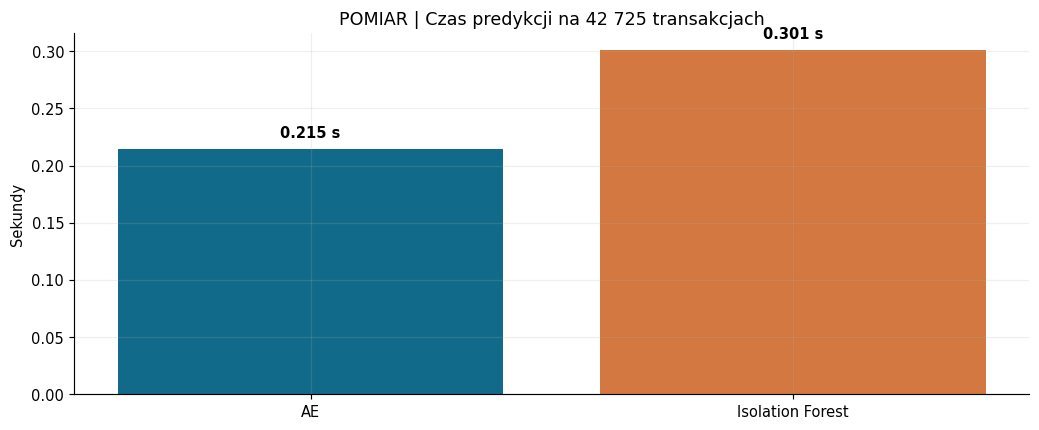

In [19]:
timing=report['timing']
performance=pd.DataFrame([
    ['Trening AE',timing['autoencoder_training_seconds'],'s'],
    ['Test AE',timing['autoencoder_test_prediction_seconds'],'s'],
    ['Trening baseline',timing['baseline_fit_seconds'],'s'],
    ['Test baseline',timing['baseline_test_prediction_seconds'],'s'],
    ['Peak VRAM',timing['peak_gpu_memory_mb'],'MB']
],columns=['Operacja','Wartość','Jednostka'])
display(performance.style.format({'Wartość':'{:.3f}'}))
fig,ax=plt.subplots(figsize=(10,4.2))
ax.bar(['AE','Isolation Forest'],[timing['autoencoder_test_prediction_seconds'],timing['baseline_test_prediction_seconds']],
       color=[COL['ae'],COL['base']])
for i,v in enumerate([timing['autoencoder_test_prediction_seconds'],timing['baseline_test_prediction_seconds']]):
    ax.text(i,v+.01,f'{v:.3f} s',ha='center',weight='bold')
ax.set(title=f'POMIAR | Czas predykcji na {N:,} transakcjach'.replace(',',' '),ylabel='Sekundy')
fig.tight_layout();savefig(fig,'13_czas_predykcji.png')

## 12. Ocena hipotezy badawczej i kryterium jakości

**Hipoteza dotycząca MSE.** Wyniki wskazują na wyraźne zróżnicowanie błędu rekonstrukcji między wykrytymi fraudami a transakcjami prawidłowymi. Obserwacje wspierają zasadność stosowania MSE do detekcji anomalii, jednak brak surowych wyników dla wszystkich transakcji uniemożliwia niezależną weryfikację różnicy średnich w całym zbiorze testowym.

**Kryterium ilościowe.** Model osiągnął **Recall 83,97%** oraz **FPR 0,981%**. Spełniono warunek FPR, lecz nie osiągnięto zakładanego Recall ≥ 85%.

## 13. Ograniczenia badania

| Ograniczenie | Konsekwencja |
|---|---|
| Niezbalansowanie klas | Nawet niewielki FPR może powodować dużą liczbę fałszywych alarmów. |
| Zakres czasowy danych | Zbiór obejmuje dwa dni z 2013 r.; nie oceniono skuteczności w innych okresach. |
| Brak historii klienta | Model nie uwzględnia indywidualnych wzorców zachowania. |
| Anonimizacja cech PCA | Ograniczona możliwość interpretacji znaczenia poszczególnych cech. |
| Oszustwa niewykryte | 38 przypadków nie przekroczyło progu detekcji. |
| Liczebność klasy fraud w teście | Wartość Recall jest wrażliwa na pojedyncze dodatkowe wykrycia. |
| Wielokrotne strojenie | Możliwe dopasowanie hiperparametrów do zbioru walidacyjnego. |
| Zakres udostępnionych artefaktów | Brak surowych wyników MSE dla wszystkich transakcji ogranicza analizy progowe. |

## 14. Wnioski końcowe

Autoenkoder osiągnął na niezależnym zbiorze testowym **Recall 83,97% (199/237)** i **FPR 0,981% (417/42 488)**. W porównaniu z Isolation Forest uzyskał większą wykrywalność oszustw (**53,16% Recall dla modelu referencyjnego**) oraz wyższe PR-AUC (**0,745 wobec 0,271**). Potwierdzono tym samym przewagę autoenkodera w warunkach przeprowadzonego eksperymentu.

Rozkład błędu rekonstrukcji wskazuje na możliwość odróżniania znacznej części oszustw od transakcji prawidłowych. Jednocześnie **38 niewykrytych fraudów** charakteryzowało się MSE poniżej przyjętego progu, co ogranicza czułość metody. Istotnym wyzwaniem pozostaje również liczba fałszywych alarmów.

**Nie spełniono łącznego kryterium Recall ≥ 85% i FPR < 1%**, choć warunek dotyczący FPR został osiągnięty.